# Proyecto MLOps completo — Clasificación de vinos

Los **tres challenges** de la sección, concatenados en un solo notebook para ejecución continua:

1. **Challenge 1 — Datos y EDA:** cargar, validar, split estratificado, análisis solo sobre train, guardar `train.csv`, `test.csv`, `data_contract.json`.
2. **Challenge 2 — Entrenamiento:** pipelines reproducibles, comparar 3 modelos con validación cruzada, optimizar hiperparámetros, elegir campeón sin tocar test → `champion_model.joblib`, `training_metadata.json`, `cv_results.csv`.
3. **Challenge 3 — Evaluación y despliegue:** abrir test UNA vez, evaluar, función de inferencia, predicción por lotes → `test_metrics.json`, `batch_predictions.csv`.

> **Regla de oro MLOps:** el conjunto de test se crea en el Challenge 1 y se *sella* — no se explora ni se usa hasta el Challenge 3.

## 0. Setup común y generación del dataset


In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 42

# Estructura de carpetas del proyecto
PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"
for d in (RAW_DATA_DIR, PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Generamos data/raw/wine.csv desde sklearn (el notebook queda autocontenido).
# En el ejercicio original este archivo ya estaría en data/raw/.
_wine = load_wine(as_frame=True)
_wine.frame.to_csv(RAW_DATA_DIR / "wine.csv", index=False)
print("wine.csv creado en data/raw/ ->", _wine.frame.shape)

wine.csv creado en data/raw/ -> (178, 14)


---
# Challenge 1 — Datos y análisis exploratorio

**Entrada:** `data/raw/wine.csv` · **Salidas:** `train.csv`, `test.csv`, `data_contract.json`

## 1.1 Carga y profiling

In [ ]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
# Profiling: forma, tipos, nulos, duplicados, distribución del target
print("Forma:", df.shape)
print("\nTipos de dato:"); print(df.dtypes.value_counts())
print("\nNulos por columna (total):", int(df.isnull().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("\nDistribución del target:")
print(df["target"].value_counts().sort_index())
print("\nProporción por clase:")
print((df["target"].value_counts(normalize=True).sort_index()*100).round(1))

Forma: (178, 14)

Tipos de dato:
float64    13
int64       1
Name: count, dtype: int64

Nulos por columna (total): 0
Filas duplicadas: 0

Distribución del target:
target
0    59
1    71
2    48
Name: count, dtype: int64

Proporción por clase:
target
0    33.1
1    39.9
2    27.0
Name: proportion, dtype: float64


**Conclusión de calidad:**

> El dataset tiene 178 filas y 14 columnas (13 numéricas y el `target`), sin valores nulos ni filas duplicadas, por lo que no necesita limpieza. El target tiene 3 clases con un pequeño desbalance (clase 1 ≈ 40 %, clases 0 y 2 ≈ 33 % y 27 %); el desbalance es leve pero suficiente para justificar un split estratificado. Todas las variables presentan escalas muy distintas por lo que se va a necesitar estandarizar para los modelos sensibles a escala.

## 1.2 Split train/test

In [ ]:
TEST_SIZE = 0.2
train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["target"], random_state=RANDOM_STATE
)

# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Proporción de clases conservada (estratificación):")
print(pd.DataFrame({
    "train": train_df["target"].value_counts(normalize=True).sort_index().round(3),
    "test":  test_df["target"].value_counts(normalize=True).sort_index().round(3),
}))

Train: (142, 14) | Test: (36, 14)
Proporción de clases conservada (estratificación):
        train   test
target              
0       0.331  0.333
1       0.401  0.389
2       0.268  0.278


## 1.3 EDA sobre entrenamiento

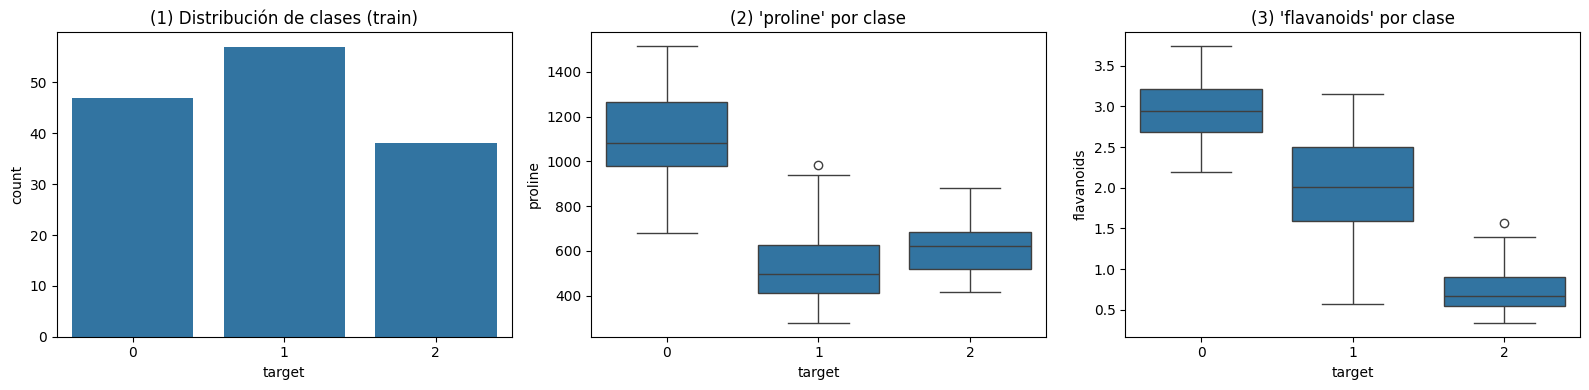

In [ ]:
# (1) Distribución de clases
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="target", data=train_df, ax=axes[0])
axes[0].set_title("(1) Distribución de clases (train)")

# (2) Boxplot de una variable de gran escala por clase
sns.boxplot(x="target", y="proline", data=train_df, ax=axes[1])
axes[1].set_title("(2) 'proline' por clase")

# (3) Boxplot de un flavonoide (muy discriminante en wine)
sns.boxplot(x="target", y="flavanoids", data=train_df, ax=axes[2])
axes[2].set_title("(3) 'flavanoids' por clase")
plt.tight_layout(); plt.show()

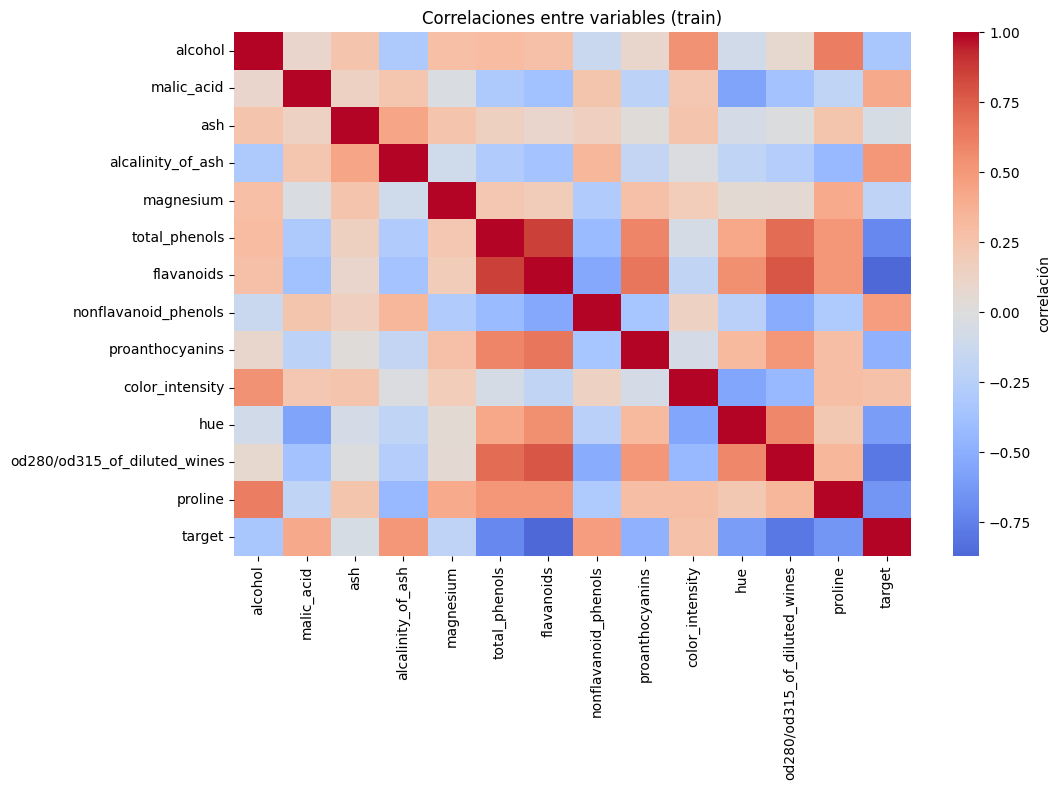

Top 5 features más correlacionadas con el target:
flavanoids                      0.870
od280/od315_of_diluted_wines    0.784
total_phenols                   0.714
proline                         0.639
hue                             0.606
Name: target, dtype: float64


In [ ]:
# (4) Mapa de correlaciones (solo train)
plt.figure(figsize=(11, 8))
sns.heatmap(train_df.corr(numeric_only=True), cmap="coolwarm", center=0,
            annot=False, cbar_kws={"label": "correlación"})
plt.title("Correlaciones entre variables (train)")
plt.tight_layout(); plt.show()

# Correlación absoluta de cada feature con el target (ranking de señal)
corr_target = train_df.corr(numeric_only=True)["target"].drop("target").abs().sort_values(ascending=False)
print("Top 5 features más correlacionadas con el target:")
print(corr_target.head(5).round(3))

**Hallazgos:**

1. **`flavanoids`, `proline` y `od280/od315_of_diluted_wines` son las variables más influyentes** (presentan la mayor correlación con el target).

2. Hay correlaciones fuertes entre features (p. ej. varios fenoles entre sí) por lo que hay redundancia, lo que afecta la importancia individual de cada variable.

## 1.4 Persistencia de datos y contrato

In [ ]:
# Reinicia índices y guarda sin el índice
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# Contrato de datos: la "fuente de verdad" que viaja por toda la cadena
TARGET = "target"
FEATURES = [c for c in df.columns if c != TARGET]
data_contract = {
    "target": TARGET,
    "features": FEATURES,
    "classes": sorted(int(c) for c in df[TARGET].unique()),
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(data_contract, indent=2, ensure_ascii=False), encoding="utf-8")

assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")
print("Features:", len(FEATURES), "| Target:", TARGET)

Challenge 1 completado.
Features: 13 | Target: target


---
# Challenge 2 — Entrenamiento y selección del modelo

**Entradas:** `train.csv`, `data_contract.json` · **Salidas:** `champion_model.joblib`, `training_metadata.json`, `cv_results.csv`

> **No se carga `test.csv` en esta etapa.** Toda la selección se hace con validación cruzada sobre train.

## 2.1 Carga de artefactos

In [ ]:
train_df = pd.read_csv(PROCESSED_DATA_DIR / "train.csv")
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))

X_train = train_df[contract["features"]]
y_train = train_df[contract["target"]]
feature_columns = contract["features"]
print("X_train:", X_train.shape, "| y_train:", y_train.shape)

X_train: (142, 13) | y_train: (142,)


## 2.2 Preprocesadores

In [ ]:
# Todas las features de wine son numéricas.
# Preprocesador para ÁRBOLES: solo imputación por mediana (no necesitan escala).
tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), feature_columns),
])

# Preprocesador para modelos SENSIBLES A ESCALA (LogReg, KNN): imputación + estandarización.
scaled_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), feature_columns),
])
print("Preprocesadores creados.")

Preprocesadores creados.


**Pregunta:** ¿por qué el `StandardScaler` debe estar dentro del pipeline y no ajustarse antes de la validación cruzada?

> Porque si se ajusta antes de la CV, el scaler calcula la media y la desviación usando todos los datos de train, incluidos los que hacen parte de la validación. Eso filtra información de la validación hacia el preprocesamiento (**data leakage**).

## 2.3 Modelos candidatos

In [ ]:
models = {
    "DecisionTree": Pipeline([
        ("prep", tree_preprocessor),
        ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "LogisticRegression": Pipeline([
        ("prep", scaled_preprocessor),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "KNN": Pipeline([
        ("prep", scaled_preprocessor),
        ("clf", KNeighborsClassifier()),
    ]),
}
print("Modelos candidatos:", list(models))

Modelos candidatos: ['DecisionTree', 'LogisticRegression', 'KNN']


## 2.4 Comparación inicial con validación cruzada

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="accuracy",
                            return_train_score=True)
    rows.append({
        "model": name,
        "train_acc_mean": scores["train_score"].mean(),
        "val_acc_mean": scores["test_score"].mean(),
        "val_acc_std": scores["test_score"].std(),
    })

initial_comparison = pd.DataFrame(rows).sort_values("val_acc_mean", ascending=False).reset_index(drop=True)
initial_comparison.round(4)

,model,train_acc_mean,val_acc_mean,val_acc_std
0,LogisticRegression,1.0000,0.9791,0.0277
1,KNN,0.9771,0.9507,0.0353
2,DecisionTree,1.0000,0.9022,0.0586


## 2.5 Optimización de hiperparámetros (GridSearchCV)

In [ ]:
param_grids = {
    "DecisionTree": {
        "clf__max_depth": [3, 5, 7, None],
        "clf__min_samples_leaf": [1, 3, 5],
    },
    "LogisticRegression": {
        "clf__C": [0.1, 1.0, 10.0],
    },
    "KNN": {
        "clf__n_neighbors": [3, 5, 7, 11],
        "clf__weights": ["uniform", "distance"],
    },
}

searches = {}
tuned_rows = []
for name, pipe in models.items():
    gs = GridSearchCV(pipe, param_grids[name], scoring="accuracy", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    tuned_rows.append({
        "model": name,
        "best_cv_acc": gs.best_score_,
        "best_params": gs.best_params_,
    })

tuned_comparison = pd.DataFrame(tuned_rows).sort_values("best_cv_acc", ascending=False).reset_index(drop=True)
tuned_comparison

,model,best_cv_acc,best_params
0,LogisticRegression,0.979064,{'clf__C': 1.0}
1,KNN,0.957882,"{'clf__n_neighbors': 7, 'clf__weights': 'unifo..."
2,DecisionTree,0.902217,"{'clf__max_depth': 5, 'clf__min_samples_leaf': 1}"


## 2.6 Selección y persistencia del campeón

In [ ]:
# Campeón = mayor best_score_ de CV (sin mirar test)
champion_name = max(searches, key=lambda n: searches[n].best_score_)
champion = searches[champion_name].best_estimator_
champion_cv_acc = searches[champion_name].best_score_

print(f"Campeón: {champion_name}  (CV accuracy = {champion_cv_acc:.4f})")

# Persistencia
joblib.dump(champion, ARTIFACTS_DIR / "champion_model.joblib")

training_metadata = {
    "champion": champion_name,
    "cv_accuracy": round(float(champion_cv_acc), 4),
    "best_params": searches[champion_name].best_params_,
    "cv_folds": 5,
    "random_state": RANDOM_STATE,
}
(ARTIFACTS_DIR / "training_metadata.json").write_text(
    json.dumps(training_metadata, indent=2, ensure_ascii=False), encoding="utf-8")

# cv_results.csv: tabla comparativa inicial + tuneada
cv_results = initial_comparison.merge(
    tuned_comparison[["model", "best_cv_acc"]], on="model", how="left")
cv_results.to_csv(REPORTS_DIR / "cv_results.csv", index=False)

assert (ARTIFACTS_DIR / "champion_model.joblib").exists()
assert (ARTIFACTS_DIR / "training_metadata.json").exists()
assert (REPORTS_DIR / "cv_results.csv").exists()
print("Challenge 2 completado.")
cv_results.round(4)

Campeón: LogisticRegression  (CV accuracy = 0.9791)
Challenge 2 completado.


,model,train_acc_mean,val_acc_mean,val_acc_std,best_cv_acc
0,LogisticRegression,1.0000,0.9791,0.0277,0.9791
1,KNN,0.9771,0.9507,0.0353,0.9579
2,DecisionTree,1.0000,0.9022,0.0586,0.9022


**Justificación de la selección:**

> Se elige LogisticRegression por tener el mayor accuracy de CV tras la optimización, con baja desviación entre folds. La brecha train–validación es pequeña, lo que indica poco sobreajuste. En caso de empate práctico con LogisticRegression, esta última sería preferible por ser más simple, más interpretable y más rápida en inferencia; el árbol gana interpretabilidad visual pero tiende a mayor varianza, y KNN es sensible a la dimensionalidad y costoso en predicción.

---
# Challenge 3 — Evaluación final e inferencia

**Entradas:** `test.csv`, `data_contract.json`, `champion_model.joblib` · **Salidas:** `test_metrics.json`, `batch_predictions.csv`

> Ahora — y **solo ahora** — se abre el conjunto de test.

## 3.1 Carga del modelo y del test

In [ ]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 3.2 Evaluación final

Accuracy test : 0.9722
F1 macro test : 0.9710

Reporte por clase:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



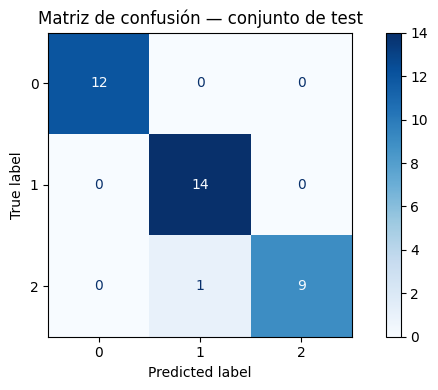

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test : {accuracy:.4f}")
print(f"F1 macro test : {f1_macro:.4f}")
print("\nReporte por clase:\n")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión — conjunto de test")
plt.tight_layout(); plt.show()

**Análisis:**

>Se logra una división de clases casi exacta teniendo un único error sobre las prediciones.

## 3.3 Función de inferencia

In [ ]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # 1. verifica columnas faltantes (contrato de datos)
    missing = set(feature_columns) - set(records.columns)
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {sorted(missing)}")

    # 2. selecciona y ORDENA las columnas como en el entrenamiento (ignora extras)
    X = records[feature_columns].copy()

    # 3. predicción + probabilidades por clase
    preds = model.predict(X)
    output = pd.DataFrame({"prediction": preds}, index=records.index)
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        for i, clase in enumerate(model.classes_):
            output[f"proba_{clase}"] = proba[:, i]
    return output

# prueba rápida de la validación de esquema
try:
    predict(X_test.iloc[:, :3])
except ValueError as e:
    print("Validación OK ->", e)

Validación OK -> Faltan columnas requeridas: ['alcalinity_of_ash', 'color_intensity', 'flavanoids', 'hue', 'magnesium', 'nonflavanoid_phenols', 'od280/od315_of_diluted_wines', 'proanthocyanins', 'proline', 'total_phenols']


## 3.4 Predicción por lotes

In [ ]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch = predict(new_records)
batch.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print("Predicciones por lotes guardadas en reports/batch_predictions.csv")
batch

Predicciones por lotes guardadas en reports/batch_predictions.csv


,prediction,proba_0,proba_1,proba_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


## 3.5 Reporte final

In [ ]:
test_metrics = {
    "champion": training_metadata["champion"],
    "cv_accuracy": training_metadata.get("cv_accuracy"),
    "test_accuracy": round(float(accuracy), 4),
    "test_f1_macro": round(float(f1_macro), 4),
    "n_test_samples": int(len(y_test)),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2, ensure_ascii=False), encoding="utf-8")

print(json.dumps(test_metrics, indent=2, ensure_ascii=False))

{
  "champion": "LogisticRegression",
  "cv_accuracy": 0.9791,
  "test_accuracy": 0.9722,
  "test_f1_macro": 0.971,
  "n_test_samples": 36
}


In [ ]:
# Verificación final de toda la cadena
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("\n✓ Pipeline completo (Challenges 1-2-3) ejecutado de punta a punta.")


✓ Pipeline completo (Challenges 1-2-3) ejecutado de punta a punta.


---
## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | LogisticRegression   |
| Accuracy CV | 0.9791 |
| Accuracy test | 0.9722 |
| F1 macro test | 0.9710 |
| Clases más confundidas | Clase 1 confundida por clase 2 (1 ocurrencia) |
| Principal limitación | Dataset pequeño (178 filas); el test tiene solo ~36 muestras, así que las métricas de test tienen varianza alta. |